# 7. Exploding gradient

Com ReLU, cada camada multiplica o sinal por sqrt{n/2}: com std = 0.5 e 32 unidades isso dá 2x por camada. Comparamos com ReLU + He, ambas com saída linear e MSE.

In [1]:
import sys
sys.path.append("..")

import warnings

import numpy as np

from src.datasets import load_mnist
from src.nn import MLP
from src.losses import mse
from src.optim import SGD
from src.training import train
from src.plots import plot_loss, plot_metric, plot_histograms, plot_gradient_sizes

PLOTS = "../assets/plots/"

LOSS_YLIM = (1e-3, 1e4)

In [2]:
X_train, y_train, X_val, y_val = load_mnist()

X_train = X_train[:10000]
y_train = y_train[:10000]
X_val = X_val[:2000]
y_val = y_val[:2000]

## Rede 1: ReLU + inicialização normal (std = 0.5)

Primeiro com o mesmo lr da rede saudável (0.1):

In [3]:
model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
            hidden_activation="relu", output_activation="linear",
            init="normal", init_scale=0.5)
optimizer = SGD(model.parameters(), lr=0.1)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # overflow is the point here
    for step in range(5):
        optimizer.zero_grad()
        loss = mse(model.forward(X_train[:32]), y_train[:32])
        loss.backward()
        largest_gradient = max(np.max(np.abs(p.grad)) for p in model.parameters())
        largest_weight = max(np.max(np.abs(p.data)) for p in model.parameters())
        print("step %d | loss %.2e | largest |gradient| %.2e | largest |weight| %.2e"
              % (step, float(loss.data), largest_gradient, largest_weight))
        optimizer.step()

step 0 | loss 5.19e+04 | largest |gradient| 4.01e+04 | largest |weight| 2.25e+00
step 1 | loss 2.00e+44 | largest |gradient| 2.18e+41 | largest |weight| 4.01e+03
step 2 | loss 1.25e+213 | largest |gradient| 1.53e+213 | largest |weight| 2.18e+40
step 3 | loss nan | largest |gradient| nan | largest |weight| 1.53e+212
step 4 | loss nan | largest |gradient| nan | largest |weight| nan


Em 3 passos a loss vira `inf`/`nan`. Para treinar, o lr precisa ser 100 000× menor (1e-6).

In [4]:
exploding_model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                      hidden_activation="relu", output_activation="linear",
                      init="normal", init_scale=0.5)

optimizer = SGD(exploding_model.parameters(), lr=1e-6)

exploding_history = train(exploding_model, optimizer, "mse", X_train, y_train, X_val, y_val,
                          epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 735.3502 | val loss 705.3282 | train accuracy 0.0963 | val accuracy 0.0930
epoch    2 | train loss 411.5099 | val loss 396.2908 | train accuracy 0.0963 | val accuracy 0.0980
epoch    3 | train loss 294.3491 | val loss 286.6828 | train accuracy 0.0960 | val accuracy 0.1025
epoch    4 | train loss 233.4153 | val loss 226.6866 | train accuracy 0.0989 | val accuracy 0.1070
epoch    5 | train loss 188.7818 | val loss 185.5338 | train accuracy 0.0984 | val accuracy 0.1010
epoch    6 | train loss 159.3592 | val loss 157.2180 | train accuracy 0.0984 | val accuracy 0.0980
epoch    7 | train loss 136.7062 | val loss 134.7361 | train accuracy 0.0964 | val accuracy 0.1030
epoch    8 | train loss 119.0955 | val loss 118.1867 | train accuracy 0.0970 | val accuracy 0.0980
epoch    9 | train loss 105.6516 | val loss 105.0380 | train accuracy 0.0998 | val accuracy 0.1055
epoch   10 | train loss 94.1090 | val loss 94.7262 | train accuracy 0.0977 | val accuracy 0.1000


Mesmo assim a acurácia fica no acaso (~10%); a loss só cai porque a saída encolhe valores enormes.

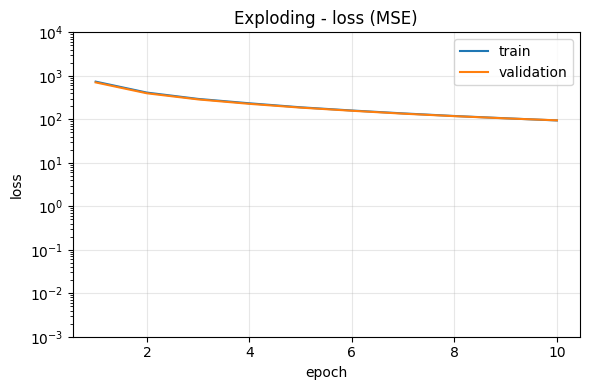

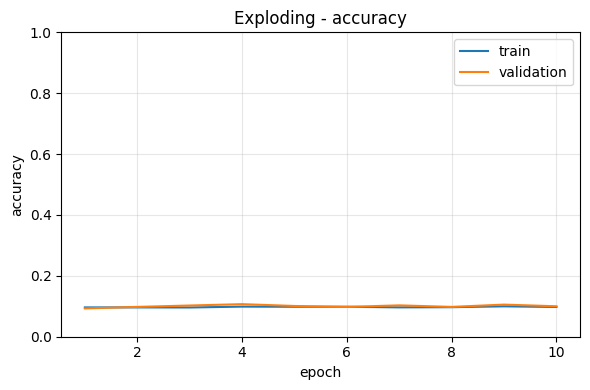

In [5]:
plot_loss(exploding_history, title="Exploding - loss (MSE)", save_path=PLOTS + "exploding_loss.png",
          ylim=LOSS_YLIM, log_y=True)
plot_metric(exploding_history, "accuracy", title="Exploding - accuracy", save_path=PLOTS + "exploding_accuracy.png", ylim=(0, 1))

Gradientes de $10^3$–$10^4$ (contra ~$10^{-2}$ na rede saudável) e ativações que dobram a cada camada.

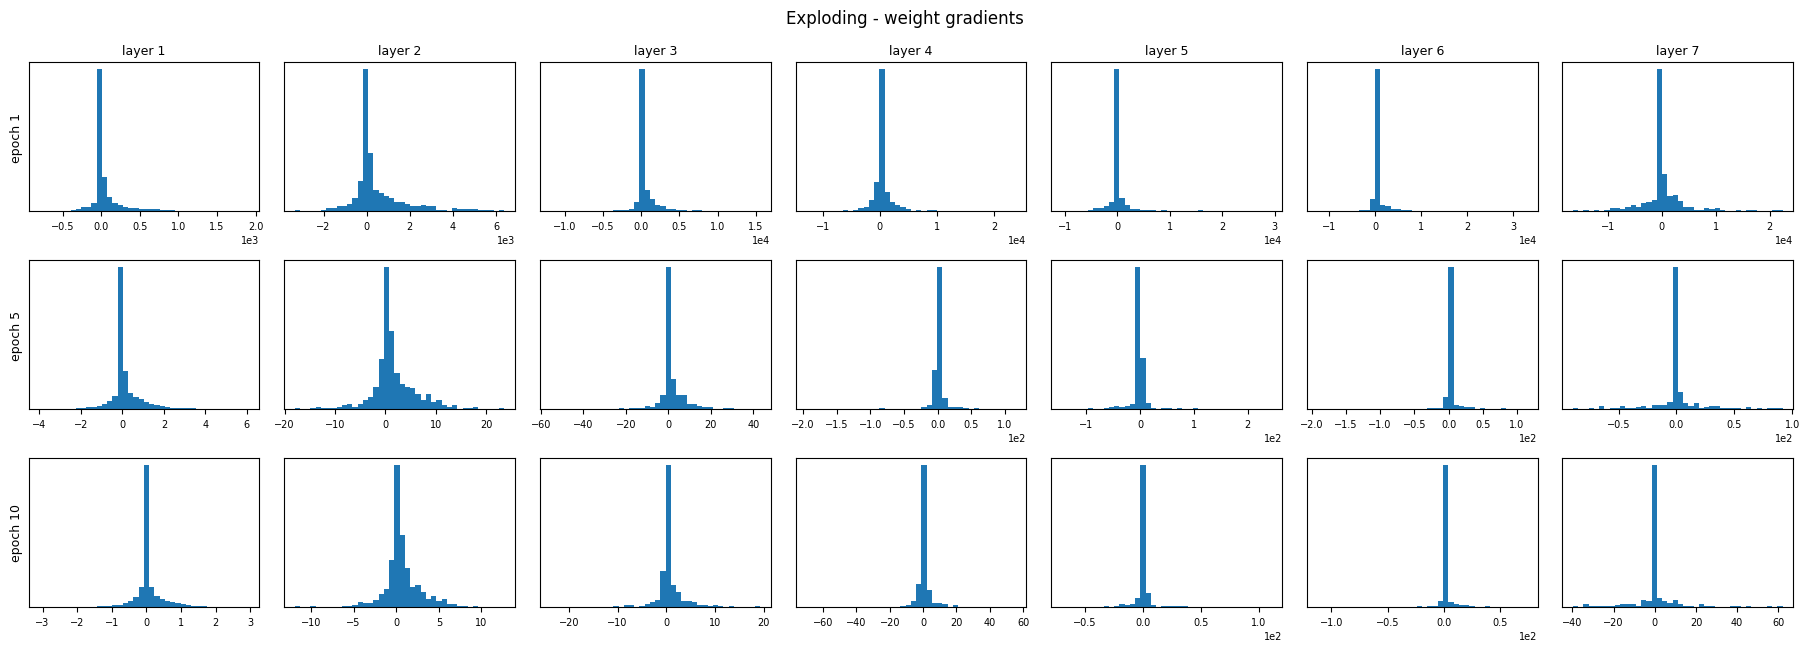

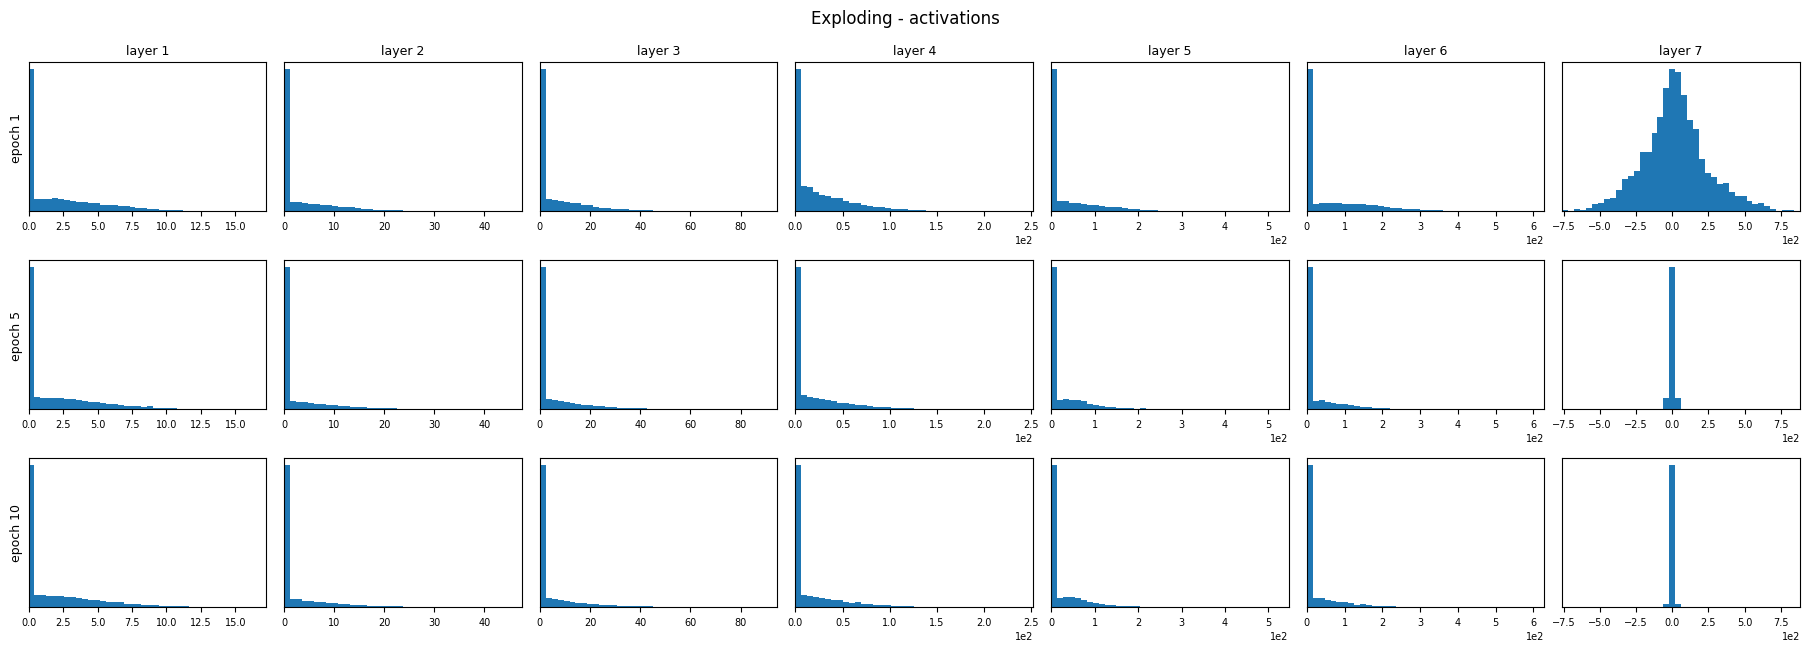

In [6]:
plot_histograms(exploding_history, "gradients", title="Exploding - weight gradients", save_path=PLOTS + "exploding_gradients.png")
plot_histograms(exploding_history, "activations", title="Exploding - activations", save_path=PLOTS + "exploding_activations.png", share_x="column")

## Rede 2: ReLU + inicialização He

In [7]:
healthy_model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                    hidden_activation="relu", output_activation="linear", init="he")

optimizer = SGD(healthy_model.parameters(), lr=0.1)

healthy_mse_history = train(healthy_model, optimizer, "mse", X_train, y_train, X_val, y_val,
                            epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.0592 | val loss 0.0636 | train accuracy 0.6995 | val accuracy 0.6345
epoch    2 | train loss 0.0425 | val loss 0.0477 | train accuracy 0.8031 | val accuracy 0.7385
epoch    3 | train loss 0.0338 | val loss 0.0392 | train accuracy 0.8447 | val accuracy 0.7965
epoch    4 | train loss 0.0290 | val loss 0.0346 | train accuracy 0.8681 | val accuracy 0.8210
epoch    5 | train loss 0.0243 | val loss 0.0301 | train accuracy 0.8932 | val accuracy 0.8455
epoch    6 | train loss 0.0222 | val loss 0.0278 | train accuracy 0.9009 | val accuracy 0.8555
epoch    7 | train loss 0.0242 | val loss 0.0299 | train accuracy 0.8941 | val accuracy 0.8505
epoch    8 | train loss 0.0189 | val loss 0.0253 | train accuracy 0.9173 | val accuracy 0.8670
epoch    9 | train loss 0.0168 | val loss 0.0229 | train accuracy 0.9251 | val accuracy 0.8705
epoch   10 | train loss 0.0171 | val loss 0.0236 | train accuracy 0.9237 | val accuracy 0.8680


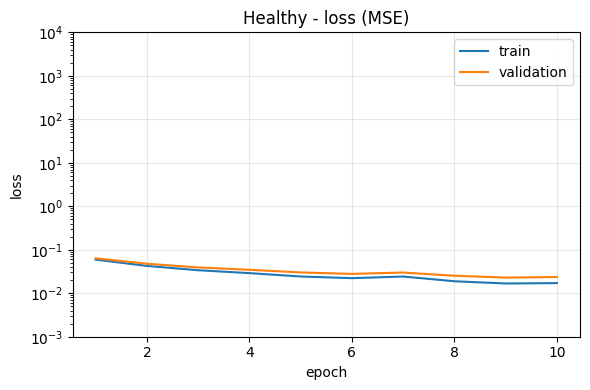

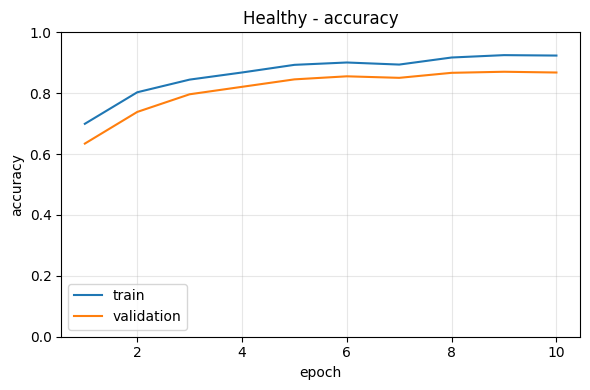

In [8]:
plot_loss(healthy_mse_history, title="Healthy - loss (MSE)", save_path=PLOTS + "healthy_mse_loss.png",
          ylim=LOSS_YLIM, log_y=True)
plot_metric(healthy_mse_history, "accuracy", title="Healthy - accuracy", save_path=PLOTS + "healthy_mse_accuracy.png", ylim=(0, 1))

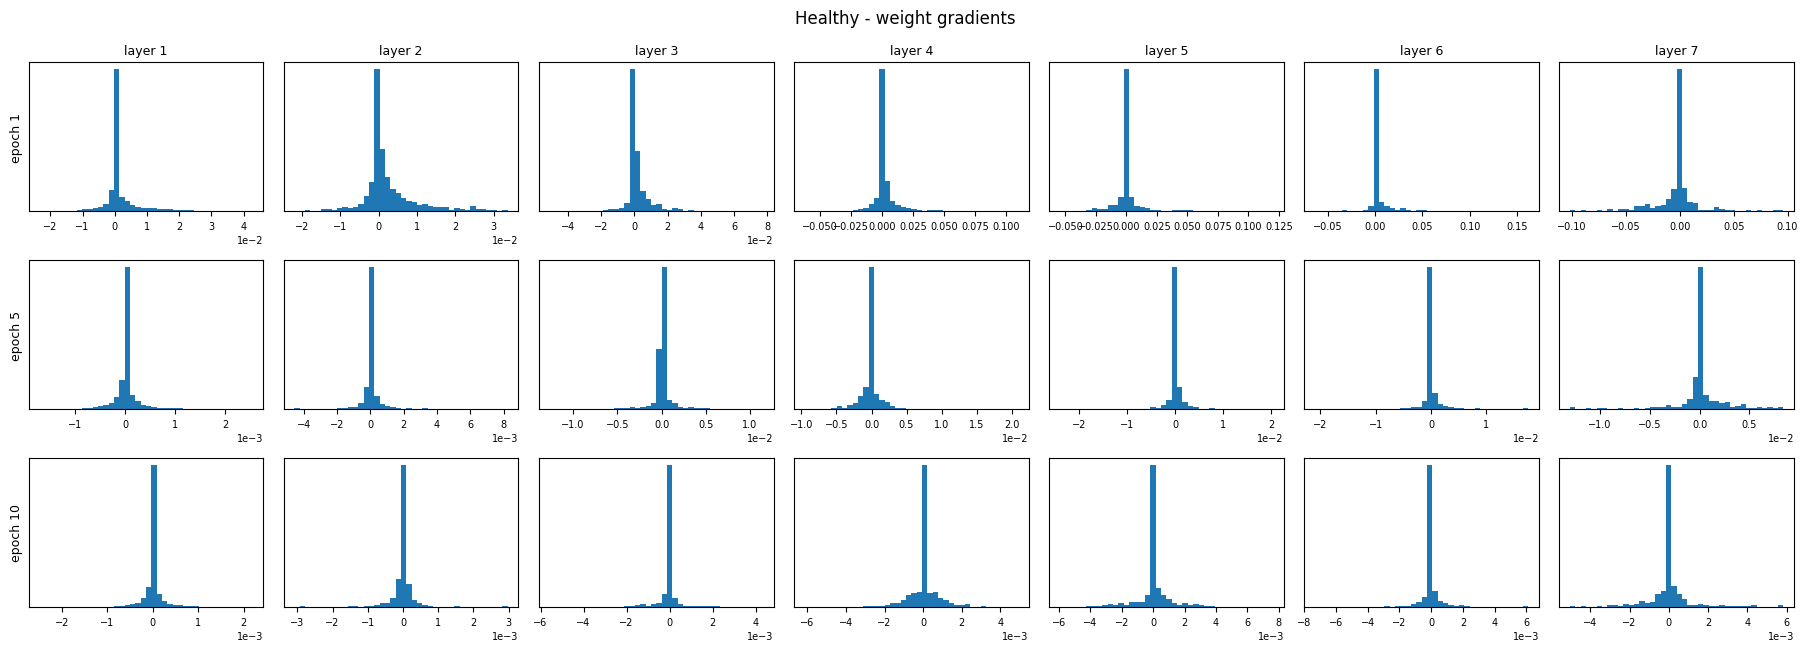

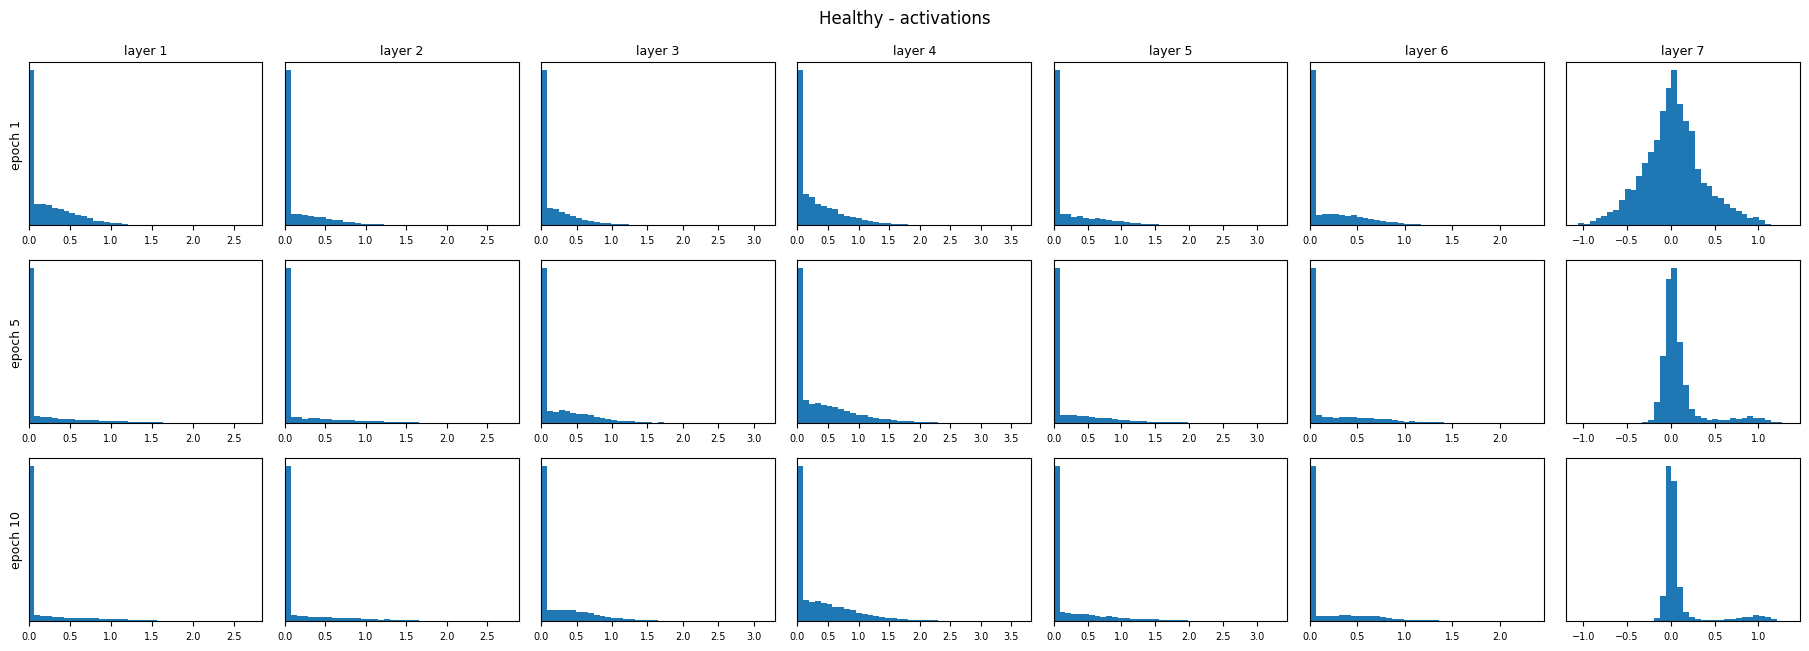

In [9]:
plot_histograms(healthy_mse_history, "gradients", title="Healthy - weight gradients", save_path=PLOTS + "healthy_mse_gradients.png")
plot_histograms(healthy_mse_history, "activations", title="Healthy - activations", save_path=PLOTS + "healthy_mse_activations.png", share_x="column")

## Comparação: ativações e gradientes por camada

Média absoluta por camada em escala log, mesmo eixo y nas duas redes.

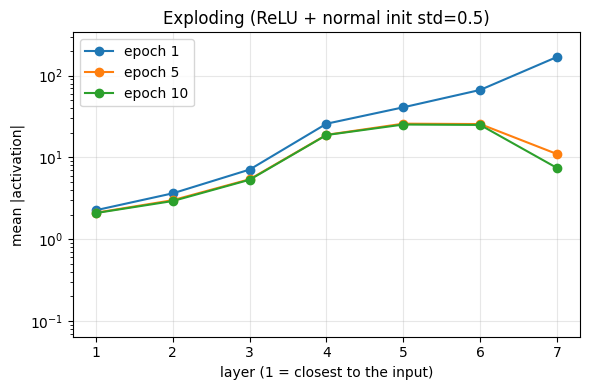

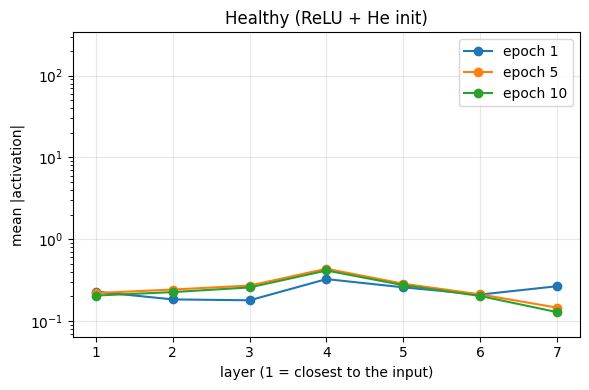

In [10]:
import matplotlib.pyplot as plt


def plot_activation_sizes(history, title, save_path, ylim):
    figure = plt.figure(figsize=(6, 4))
    for snapshot in history["snapshots"]:
        sizes = [np.mean(np.abs(a)) for a in snapshot["activations"]]
        plt.plot(range(1, len(sizes) + 1), sizes, marker="o", label="epoch " + str(snapshot["epoch"]))
    plt.yscale("log")
    plt.ylim(ylim)
    plt.xlabel("layer (1 = closest to the input)")
    plt.ylabel("mean |activation|")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    figure.tight_layout()
    figure.savefig(save_path, dpi=120)
    plt.show()


def size_range(kind):
    sizes = [np.mean(np.abs(values)) for h in (exploding_history, healthy_mse_history)
             for snapshot in h["snapshots"] for values in snapshot[kind]]
    sizes = [s for s in sizes if s > 0]
    return (min(sizes) / 2, max(sizes) * 2)


ACT_YLIM = size_range("activations")
GRAD_YLIM = size_range("gradients")

plot_activation_sizes(exploding_history, "Exploding (ReLU + normal init std=0.5)", PLOTS + "exploding_activation_sizes.png", ACT_YLIM)
plot_activation_sizes(healthy_mse_history, "Healthy (ReLU + He init)", PLOTS + "healthy_mse_activation_sizes.png", ACT_YLIM)

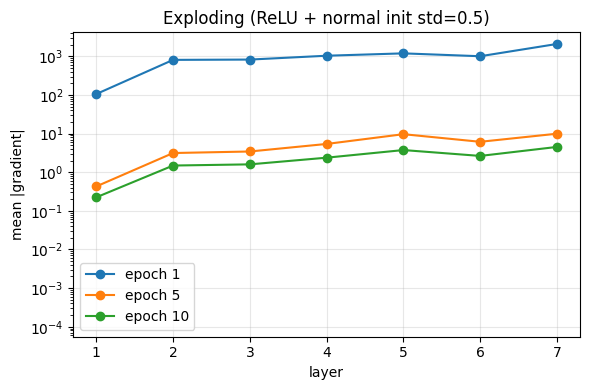

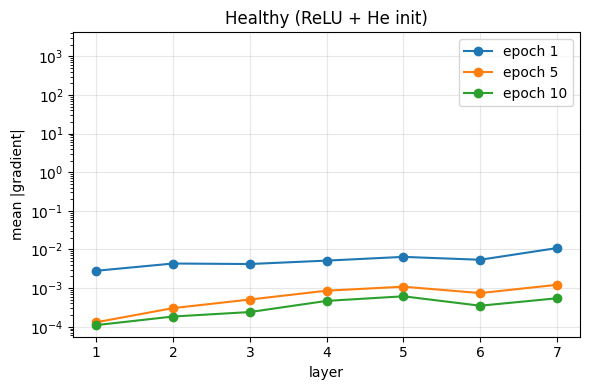

In [11]:
plot_gradient_sizes(exploding_history, title="Exploding (ReLU + normal init std=0.5)", save_path=PLOTS + "exploding_gradient_sizes.png", ylim=GRAD_YLIM)
plot_gradient_sizes(healthy_mse_history, title="Healthy (ReLU + He init)", save_path=PLOTS + "healthy_mse_gradient_sizes.png", ylim=GRAD_YLIM)

## Conclusões

Pesos grandes demais fazem ativações e gradientes crescerem exponencialmente com a profundidade; a inicialização He mantém o fator por camada perto de 1.